# 5. Experiments

What was tried besides the shipped model, and why each one was or was not kept. Selection used validation regions only. Test comparisons were made once, on the same regions.

`RUN_EXPERIMENTS = False` skips the slow cells. Tables are computed from `results/`; the runs not in `results/` are shown as copies of their real logs.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "lulc").is_dir())
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
RES = ROOT / "results"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "axes.grid": False})

# Where the exported data and full runs live. Set LULC_BASE to your own folder. Not needed to read or re-run this notebook.
BASE = os.environ.get("LULC_BASE", "/home/jovyan/vault/lulc" if Path("/home/jovyan/vault/lulc").is_dir() else str(ROOT / "data"))
OUT, RUNS, RUNS_MY = f"{BASE}/raw", f"{BASE}/runs", f"{BASE}/runs_multiyear"
PROJECT = os.environ.get("EE_PROJECT", "")     # your own Earth Engine project; no ID is stored in the repo
V12 = "V12_window3_balanced_stats"             # the shipped model

RUN_EXPERIMENTS = False     # True re-runs the slow steps below. They need Earth Engine and/or a GPU. Left False, nothing is downloaded or trained.
print("repo:", ROOT.name, "| data folder found:", Path(OUT).is_dir(), "|", "RUN_EXPERIMENTS =", RUN_EXPERIMENTS)

repo: sentinel1-lulc | data folder found: False | RUN_EXPERIMENTS = False


## 1. Model variants on validation regions
A new variant replaces V12 only if its mean over 3 seeds is at least 0.02 higher (`docs/REFERENCES_ROUND2.md`).
Compare within a group only, because the two groups use different training and validation data.

In [2]:
display(pd.read_csv(RES / "tables" / "variant_table.csv"))
my = pd.read_csv(RES / "tables" / "variant_table.csv"); my = my[my.trained == "trained on 2021-2024"].set_index("variant")["mean"]
base = my[V12]
print({v: f"{my[v] - base:+.3f}" for v in my.index if v != V12}, "against V12", base, "| replaces V12 (at least +0.02):", [v for v in my.index if my[v] - base >= 0.02])

,trained,variant,mean,std,seeds
0,trained on 2021,V0_scratch_1m,0.466,0.010,3
1,trained on 2021,V11_window3_balanced,0.628,0.007,3
2,trained on 2021,V12_window3_balanced_stats,0.646,0.010,3
3,trained on 2021,V1_imagenet_1m,0.597,0.008,3
4,trained on 2021,V5_window3_stats,0.639,0.019,3
5,trained on 2021,V6_window3_loss,0.609,0.019,3
6,trained on 2021,V7_window3_speckle,0.633,0.003,3
7,trained on 2021,V8_window3_all,0.628,0.027,3
8,trained on 2021,V9_window3_regularised,0.604,0.026,3
9,trained on 2021-2024,V12_window3_balanced_stats,0.616,0.002,3


{'V16_window3_boundary': '+0.003', 'V17_window3_fullres': '-0.003', 'V18_window5': '-0.003'} against V12 0.616 | replaces V12 (at least +0.02): []


In [3]:
# V16 boundary loss, V17 full-resolution branch, V18 5-month window
if RUN_EXPERIMENTS:

    %run scripts/train_all.py --data $OUT --out $RUNS_MY --variants V16_window3_boundary V17_window3_fullres V18_window5 --seeds 0 1 2 --workers 0

## 2. Training on 2021 only, or on 2021 to 2024
All rows without the no-data fill, so they compare like with like. These are the runs that decided which model ships.

In [4]:
rows = []
for y in (2025, 2026):
    for name, folder in (("trained on 2021 only", f"runs/eval_{V12}_y{y}_shipped"), ("trained on 2021-2024 (shipped)", f"runs_multiyear/eval_{V12}_y{y}"),
                         ("2021-2024, boundary loss (V16)", f"runs_multiyear/eval_V16_window3_boundary_y{y}")):
        m = json.loads((RES / folder / "metrics.json").read_text())
        rows.append({"year": y, "model": name, **{k: round(m[s]["miou"], 3) for k, s in (("mIoU", "dw"), ("cities", "dw_cities"), ("rural", "dw_rural"))}, "OA": round(m["dw"]["oa"], 3),
                     "Water IoU": round(m["dw"]["per_class_iou"]["Water"], 3), "regions": m["dw"]["n_cities"]})
display(pd.DataFrame(rows))

,year,model,mIoU,cities,rural,OA,Water IoU,regions
0,2025,trained on 2021 only,0.485,0.465,0.476,0.685,0.394,39
1,2025,trained on 2021-2024 (shipped),0.540,0.489,0.538,0.723,0.544,39
2,2025,"2021-2024, boundary loss (V16)",0.531,0.495,0.517,0.715,0.558,39
3,2026,trained on 2021 only,0.553,0.513,0.517,0.738,0.573,39
4,2026,trained on 2021-2024 (shipped),0.557,0.506,0.553,0.741,0.582,39
5,2026,"2021-2024, boundary loss (V16)",0.545,0.494,0.542,0.732,0.559,39


**Saved log from the original run on Data Lab: pooled boundary F1, in the order 2025 then 2026; 2021-only, shipped, V16 in each.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
################ 2025: shipped V12 (2021 only)
Boundary F1 vs Dynamic World (1 px tolerance, pooled): raw 0.319, after 3-month majority 0.318. Predicted border pixels / reference border pixels: 0.70 (above 1 = speckly
################ 2025: V12 trained 2021-2024
Boundary F1 vs Dynamic World (1 px tolerance, pooled): raw 0.344, after 3-month majority 0.345. Predicted border pixels / reference border pixels: 0.70 (above 1 = speckly
################ 2025: V16 trained 2021-2024 (boundary loss)
Boundary F1 vs Dynamic World (1 px tolerance, pooled): raw 0.357, after 3-month majority 0.357. Predicted border pixels / reference border pixels: 0.78 (above 1 = speckly
################ 2026: shipped V12 (2021 only)
Boundary F1 vs Dynamic World (1 px tolerance, pooled): raw 0.339, after 3-month majority 0.344. Predicted border pixels / reference border pixels: 0.75 (above 1 = speckly
################ 2026: V12 trained 2021-2024
Boundary F1 vs Dynamic World (1 px tolerance, pooled): raw 0.365, after 3-month majority 0.370. Predicted border pixels / reference border pixels: 0.74 (above 1 = speckly
################ 2026: V16 trained 2021-2024 (boundary loss)
Boundary F1 vs Dynamic World (1 px tolerance, pooled): raw 0.377, after 3-month majority 0.382. Predicted border pixels / reference border pixels: 0.85 (above 1 = speckly
```

## 3. Filling no-data months at inference
A correction to the input, not a model choice. It was compared before and after **on the test regions**, which is stated in the report. Training is unchanged.

,all regions,cities,rural
blank months (before),0.557,0.506,0.553
filled months (after),0.562,0.510,0.556


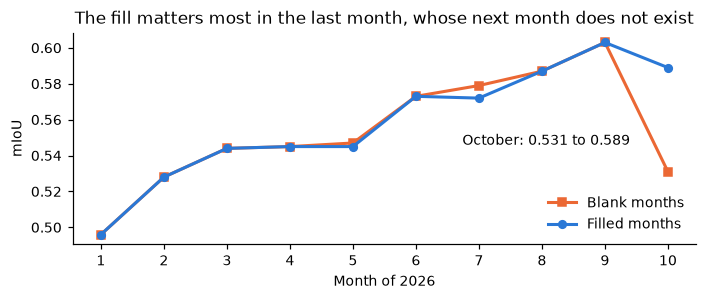

In [5]:
my = RES / "runs_multiyear"
a, b = [json.loads((my / f"eval_{V12}_2026_{k}" / "metrics.json").read_text()) for k in ("blank", "filled")]
display(pd.DataFrame({name: {"blank months (before)": round(a[k]["miou"], 3), "filled months (after)": round(b[k]["miou"], 3)} for name, k in (("all regions", "dw"), ("cities", "dw_cities"), ("rural", "dw_rural"))}))
ma, mb = [pd.read_csv(my / f"eval_{V12}_2026_{k}" / "by_month.csv", index_col=0) for k in ("blank", "filled")]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(ma.index, ma.mIoU, color="#eb6834", lw=2, marker="s", ms=5, label="Blank months")
ax.plot(mb.index, mb.mIoU, color="#2a78d6", lw=2, marker="o", ms=5, label="Filled months")
ax.text(9.4, 0.546, f"October: {ma.mIoU.iloc[-1]:.3f} to {mb.mIoU.iloc[-1]:.3f}", ha="right")
ax.set(xlabel="Month of 2026", ylabel="mIoU", title="The fill matters most in the last month, whose next month does not exist", xticks=ma.index)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

In [6]:
# The before run
if RUN_EXPERIMENTS:

    %run scripts/evaluate.py --data $OUT --runs $RUNS_MY --variant $V12 --year 2026 --skip-missing --no-fill-gaps --tag _2026_blank

## 4. How much of the error do the reference maps dispute?
The tolerant score counts a prediction as correct if it matches Dynamic World, WorldCover or Esri, so it flatters any model. It is reported next to the normal score, never instead.
Both are on the same regions here, as means per region.

In [7]:
d = RES / "runs_multiyear" / f"eval_{V12}_2021_tolerant"
same = pd.read_csv(d / "per_city.csv").dropna(subset=["tolerant_miou"])
print(len(same), "regions:", ", ".join(same.region))
display(same[["dw_miou", "wc_miou", "esri_miou", "tolerant_miou"]].mean().round(3).to_frame("mean mIoU per region"))
print("How often the other maps agree with Dynamic World, per Dynamic World class (no model involved):")
display(pd.read_csv(d / "map_agreement.csv", index_col=0))

9 regions: prague, frankfurt, milan, valencia, north_china_plain, appalachians, western_desert, great_basin, lake_balaton


,mean mIoU per region
dw_miou,0.466
wc_miou,0.432
esri_miou,0.446
tolerant_miou,0.630


How often the other maps agree with Dynamic World, per Dynamic World class (no model involved):


,dw_pixels,worldcover_agrees_%,esri_agrees_%,both_agree_%
Tree cover,36739261,87.3,67.2,65.7
Grass/shrub,10717234,62.4,41.8,36.4
Cropland,62362597,69.0,89.6,67.7
Built-up,97032739,61.3,96.4,60.8
Bare,22950137,63.8,54.5,54.0
Water,29906705,93.6,95.0,93.3


## 5. More training data and bigger models (2021)
Each row of scores is for the model named, against the 2021-only V12 on the same regions. Each new model used 2 seeds. These runs are not in `results/`, so these are copies of their logs.
The lines are mIoU against each map, then false change (flip rate, churn, net change) in the `model` lines.

In [8]:
# Folders for these experiments
if RUN_EXPERIMENTS:
    # 0. Paths (skip if the main notebook already defined them)
    import os, glob, shutil
    BASE = globals().get('BASE', '/home/jovyan/vault/lulc'); OUT = globals().get('OUT', f'{BASE}/raw')
    RUNS = globals().get('RUNS', f'{BASE}/runs'); PROJECT = globals().get('PROJECT', 'sar-lulc')
    def copy_baselines(dst):
        os.makedirs(dst, exist_ok=True)
        for v in ['V0_scratch_1m','V1_imagenet_1m']:
            if os.path.isdir(f'{RUNS}/{v}') and not os.path.isdir(f'{dst}/{v}'): shutil.copytree(f'{RUNS}/{v}', f'{dst}/{v}')
    print('OUT', OUT, '| RUNS', RUNS)

In [9]:
# Targeted grass and savanna sites. WARNING: edits configs/regions.yaml; restore it with git afterwards
if RUN_EXPERIMENTS:
    # 2a. Export the 4 targeted sites (coverage check first)
    GRASS = 'ethiopia_highlands cerrado_brazil kazakh_steppe texas_rangeland'
    %run scripts/ee_year_stats.py --project $PROJECT --years 2021 --regions $GRASS
    %run scripts/export_dataset.py --project $PROJECT --out $OUT --regions $GRASS
    # 2b. Make the 4 sites 'train' in regions.yaml, then retrain V12 (2 seeds) in a fresh folder
    import re
    P = 'ethiopia_highlands cerrado_brazil kazakh_steppe texas_rangeland'.split()
    s = open('configs/regions.yaml').read()
    for k in P: s = re.sub(r'(^\s*'+k+r':\s*\{[^}]*?split:\s*)test_ood', r'\1train', s, flags=re.M)
    open('configs/regions.yaml','w').write(s); print('promoted', P)
    RUNS_grass = f'{BASE}/runs_grass'; copy_baselines(RUNS_grass)
    %run scripts/train_all.py --data $OUT --out $RUNS_grass --variants V12_window3_balanced_stats --seeds 0 1 --workers 0
    # 2c. Evaluate and compare with the shipped V12 on the SAME regions
    %run scripts/evaluate.py --data $OUT --runs $RUNS_grass --variant V12_window3_balanced_stats --tag _grass
    # shipped V12 on the same config (for a fair side-by-side):
    %run scripts/evaluate.py --data $OUT --runs $RUNS --variant V12_window3_balanced_stats --tag _grass_ref
    print('Compare dw_rural, Grass/shrub IoU and Water IoU between the two. Keep only if Grass/shrub rises and Water holds.')

**Saved log from the original run on Data Lab: grass sites retrain first, then the 2021-only V12 on the same 34 regions.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
dw           mIoU 0.518 [0.424, 0.632]  OA 0.703  (34 cities)
dw_cities    mIoU 0.441 [0.358, 0.559]  OA 0.755  (5 cities)
dw_rural     mIoU 0.555 [0.444, 0.627]  OA 0.653  (29 cities)
wc           mIoU 0.617 [0.473, 0.666]  OA 0.738  (9 cities)
esri         mIoU 0.704 [0.535, 0.748]  OA 0.855  (9 cities)
model                           3.15              2.20                 0.81
model+majority3                 1.00              0.62                 2.16
dw           mIoU 0.621 [0.556, 0.672]  OA 0.770  (34 cities)
dw_cities    mIoU 0.572 [0.507, 0.616]  OA 0.860  (5 cities)
dw_rural     mIoU 0.579 [0.474, 0.645]  OA 0.683  (29 cities)
wc           mIoU 0.613 [0.491, 0.677]  OA 0.743  (9 cities)
esri         mIoU 0.678 [0.544, 0.742]  OA 0.851  (9 cities)
model                           2.83              2.06                 1.15
model+majority3                 1.22              0.98                 2.35
```

In [10]:
# Bigger encoder: ResNet-50
if RUN_EXPERIMENTS:
    # 3. Train V14 (ResNet-50), 2 seeds, then evaluate
    RUNS_r50 = f'{BASE}/runs_r50'; copy_baselines(RUNS_r50)
    %run scripts/train_all.py --data $OUT --out $RUNS_r50 --variants V14_resnet50 --seeds 0 1 --workers 0
    %run scripts/evaluate.py --data $OUT --runs $RUNS_r50 --variant V14_resnet50 --tag _r50

**Saved log from the original run on Data Lab: ResNet-50 on the same 34 regions.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
dw           mIoU 0.509 [0.415, 0.625]  OA 0.696  (34 cities)
dw_cities    mIoU 0.436 [0.349, 0.556]  OA 0.750  (5 cities)
dw_rural     mIoU 0.546 [0.430, 0.622]  OA 0.643  (29 cities)
wc           mIoU 0.637 [0.478, 0.683]  OA 0.745  (9 cities)
esri         mIoU 0.726 [0.537, 0.771]  OA 0.856  (9 cities)
model                           2.14              1.33                 1.05
model+majority3                 0.80              0.44                 1.13
```

In [11]:
# WorldCover as training labels. Read the Esri row: WorldCover is no longer independent here
if RUN_EXPERIMENTS:
    # 4a. Export the WorldCover/Esri reference for the TRAIN regions (fast; ~10 s per region)
    TRAIN_REGS = 'munich berlin hamburg cologne paris amsterdam warsaw rome madrid vienna poltava hungarian_plain black_forest sahara_algeria dehesa_spain finnish_lakeland pampas nsw_pasture kenya_savanna mongolia_steppe arabia_desert'
    %run scripts/export_reference.py --project $PROJECT --out $OUT --regions $TRAIN_REGS
    # 4b. Train V15 (WorldCover labels), 2 seeds, then evaluate (read the Esri rows, not WorldCover)
    RUNS_wc = f'{BASE}/runs_wc'; copy_baselines(RUNS_wc)
    %run scripts/train_all.py --data $OUT --out $RUNS_wc --variants V15_worldcover_labels --seeds 0 1 --workers 0
    %run scripts/evaluate.py --data $OUT --runs $RUNS_wc --variant V15_worldcover_labels --tag _wc
    print('WorldCover is now part of training: compare the ESRI rows (esri, esri_rural) with the shipped V12, not the wc rows.')

**Saved log from the original run on Data Lab: WorldCover labels.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
dw           mIoU 0.432 [0.355, 0.538]  OA 0.609  (38 cities)
dw_cities    mIoU 0.331 [0.259, 0.459]  OA 0.592  (5 cities)
dw_rural     mIoU 0.493 [0.386, 0.557]  OA 0.623  (33 cities)
wc           mIoU 0.573 [0.453, 0.697]  OA 0.733  (9 cities)
esri         mIoU 0.503 [0.352, 0.642]  OA 0.695  (9 cities)
model                           5.08              4.15                 1.46
model+majority3                 2.12              1.62                 2.26
```

In [12]:
# 12 more rural training sites. WARNING: exports and promotes sites; restore configs/regions.yaml with git afterwards
if RUN_EXPERIMENTS:
    # 1. Export the 12 new TRAIN sites and the 15 remaining rural TEST sites (coverage check first; drop any that fail).
    PROMOTED = 'amazon_para congo_forest mekong_delta java_rice india_punjab deccan_india ethiopia_highlands cerrado_brazil iowa_maize kazakh_steppe pantanal_wetland altiplano_andes'
    REMAIN_TEST = 'thai_paddy bangladesh_delta madagascar_plateau patagonia_steppe nz_pasture scottish_highlands iceland_tundra tibetan_plateau california_valley texas_rangeland sahel_niger siberia_taiga australia_outback'
    %run scripts/ee_year_stats.py --project $PROJECT --years 2021 --regions $PROMOTED
    # if any promoted tile returns 0 scenes, remove it from PROMOTED before exporting (it must have training data)
    %run scripts/export_dataset.py --project $PROJECT --out $OUT --regions $PROMOTED $REMAIN_TEST
    # 2. Retrain V12 on the expanded training set, in a FRESH folder so nothing is skipped.
    #    2 seeds to fit the day (add seed 2 later if time). Copy V0/V1 summaries so V12 can pick the encoder weights.
    import glob, shutil
    RUNS_rural = f'{BASE}/runs_rural'
    os.makedirs(RUNS_rural, exist_ok=True)
    for v in ['V0_scratch_1m', 'V1_imagenet_1m']:
        if os.path.isdir(f'{RUNS}/{v}') and not os.path.isdir(f'{RUNS_rural}/{v}'):
            shutil.copytree(f'{RUNS}/{v}', f'{RUNS_rural}/{v}')
    %run scripts/train_all.py --data $OUT --out $RUNS_rural --variants V12_window3_balanced_stats --seeds 0 1 --workers 0
    # 3. Evaluate the retrained model on the held-out rural test set and read dw_rural.
    %run scripts/evaluate.py --data $OUT --runs $RUNS_rural --variant V12_window3_balanced_stats --tag _rural
    %run scripts/evaluate.py --data $OUT --runs $RUNS --variant V12_window3_balanced_stats --tag _oldmodel_newtest

**Saved log from the original run on Data Lab: 12 more rural sites.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
dw           mIoU 0.500 [0.413, 0.619]  OA 0.681  (26 cities)
dw_cities    mIoU 0.412 [0.341, 0.553]  OA 0.720  (5 cities)
dw_rural     mIoU 0.521 [0.366, 0.591]  OA 0.633  (21 cities)
wc           mIoU 0.566 [0.429, 0.651]  OA 0.716  (9 cities)
esri         mIoU 0.633 [0.473, 0.716]  OA 0.822  (9 cities)
model                           5.27              3.99                 2.00
model+majority3                 1.95              1.38                 2.57
```

**Saved log from the original run on Data Lab: the 2021-only V12 on the same 26 regions.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
dw           mIoU 0.621 [0.540, 0.674]  OA 0.764  (26 cities)
dw_cities    mIoU 0.572 [0.507, 0.616]  OA 0.860  (5 cities)
dw_rural     mIoU 0.527 [0.369, 0.594]  OA 0.645  (21 cities)
wc           mIoU 0.613 [0.491, 0.677]  OA 0.743  (9 cities)
esri         mIoU 0.678 [0.544, 0.742]  OA 0.851  (9 cities)
model                           2.83              2.06                 1.15
model+majority3                 1.22              0.98                 2.35
```

## 6. Smoothing
A 3-month majority vote against averaging the probabilities over 3 months, with the same 2021-only model. The prototype uses the majority vote.

In [13]:
if RUN_EXPERIMENTS:
    # 1. Post-processing comparison on the shipped V12 (writes eval_..._postproc)
    %run scripts/evaluate.py --data $OUT --runs $RUNS --variant V12_window3_balanced_stats --prob-smooth --tag _postproc

**Saved log from the original run on Data Lab: smoothing comparison.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
dw           mIoU 0.612 [0.548, 0.659]  OA 0.760  (38 cities)
dw_cities    mIoU 0.572 [0.507, 0.616]  OA 0.860  (5 cities)
dw_rural     mIoU 0.566 [0.473, 0.627]  OA 0.676  (33 cities)
wc           mIoU 0.613 [0.491, 0.677]  OA 0.743  (9 cities)
esri         mIoU 0.678 [0.544, 0.742]  OA 0.851  (9 cities)
model                           2.83              2.06                 1.15
model+majority3                 1.22              0.98                 2.35
model+probmean3                 1.23              0.96                 1.46
```

## 7. Sharper borders
One rule judges every step, fixed before the results (`sharpness.passes_border_rule`): boundary F1 up by at least 0.02, pooled mIoU down by no more than 0.005, and no class IoU down by more than 0.05.

Every step uses the shipped V12 as its baseline. The first four rows are judged on validation regions in 2024, on 4 months. The graph head is trained on validation regions and judged on the 2025 test regions, so it has its own baseline.
V16 and V17 are also in sections 1 and 2.

In [14]:
from lulc.sharpness import passes_border_rule

def scores(row):
    return {"miou": row["mIoU"], "bf1": row["boundary_F1"], "iou": [row[c] for c in row.index if c.startswith("iou_")]}

steps = [
    ("Test-time augmentation", "validation 2024", f"sharpen_{V12}_tta/sharpen.csv", "none", "tta"),
    ("Gaussian stitching", "validation 2024", f"sharpen_{V12}_gaussian/sharpen.csv", "none", "gaussian"),
    ("CRF, mild", "validation 2024", f"crf_{V12}/crf.csv", "none", "mild"),
    ("CRF, strong", "validation 2024", f"crf_{V12}/crf.csv", "none", "strong"),
    ("Full-resolution branch (V17)", "validation 2024", f"sharpen_{V12}_v17/sharpen.csv", "none", "V17_window3_fullres"),
    ("Object vote", "test 2025", f"graph_head_{V12}/graph_head.csv", "model", "object_vote"),
    ("Graph head", "test 2025", f"graph_head_{V12}/graph_head.csv", "model", "graph_head"),
]
rows = []
for name, where, path, base, step in steps:
    t = pd.read_csv(RES / "runs_multiyear" / path)
    t = t.set_index(t.columns[0])
    b, s = scores(t.loc[base]), scores(t.loc[step])
    ok, why = passes_border_rule(b, s)
    rows.append({"step": name, "judged on": where, "baseline mIoU": b["miou"], "mIoU": s["miou"], "mIoU change": round(s["miou"] - b["miou"], 3),
                 "baseline boundary F1": b["bf1"], "boundary F1": s["bf1"], "boundary F1 change": round(s["bf1"] - b["bf1"], 3),
                 "largest class drop": round(max(0, max(x - y for x, y in zip(b["iou"], s["iou"]))), 3), "passes": ok})
border = pd.DataFrame(rows)
display(border)
print("steps that pass the rule:", list(border[border.passes].step) or "none")

,step,judged on,baseline mIoU,mIoU,mIoU change,baseline boundary F1,boundary F1,boundary F1 change,largest class drop,passes
0,Test-time augmentation,validation 2024,0.613,0.615,0.002,0.402,0.403,0.001,0.001,False
1,Gaussian stitching,validation 2024,0.613,0.614,0.001,0.402,0.402,0.000,0.001,False
2,"CRF, mild",validation 2024,0.613,0.614,0.001,0.402,0.386,-0.016,0.003,False
3,"CRF, strong",validation 2024,0.613,0.613,0.000,0.402,0.358,-0.044,0.008,False
4,Full-resolution branch (V17),validation 2024,0.613,0.609,-0.004,0.402,0.413,0.011,0.013,False
5,Object vote,test 2025,0.533,0.501,-0.032,0.345,0.214,-0.131,0.079,False
6,Graph head,test 2025,0.533,0.468,-0.065,0.345,0.198,-0.147,0.102,False


steps that pass the rule: none


No step passed, so none went on to the test regions and none is in the prototype. The largest gain in boundary F1 is V17, at +0.011, about half of what the rule asks for.
The CRF and the graph head lower boundary F1. These runs do not show the cause. A likely reason is the radar's resolution of about 20 m and the noisy labels, which this table does not test.

In [15]:
# TTA, CRF, Gaussian stitching, graph head, V17 comparison
if RUN_EXPERIMENTS:
    # 0. Paths. BASELINE is the model the steps are compared against.
    import os, glob, shutil
    BASE = globals().get('BASE', '/home/jovyan/vault/lulc'); OUT = globals().get('OUT', f'{BASE}/raw')
    RUNS = globals().get('RUNS', f'{BASE}/runs')
    RUNS_MY = f'{BASE}/runs_multiyear'; os.makedirs(RUNS_MY, exist_ok=True)
    BASELINE = 'V12_window3_balanced_stats'
    print('cwd:', os.getcwd())
    print('baseline seeds:', glob.glob(f'{RUNS_MY}/{BASELINE}/seed*/best.pt'))
    %run scripts/sharpen_eval.py --data $OUT --runs $RUNS_MY --variant $BASELINE --year 2024 --settings tta --tag _tta
    %run scripts/crf_eval.py --data $OUT --runs $RUNS_MY --variant $BASELINE --splits val --year 2024
    %run scripts/sharpen_eval.py --data $OUT --runs $RUNS_MY --variant $BASELINE --year 2024 --settings gaussian --tag _gaussian
    # %run scripts/sharpen_eval.py --data $OUT --runs $RUNS_MY --variant $BASELINE --year 2024 --settings tta+gaussian --tag _both
    %run scripts/graph_head_eval.py --data $OUT --runs $RUNS_MY --variant $BASELINE --train-splits val --eval-splits test test_ood --year 2024 --eval-year 2025
    %run scripts/sharpen_eval.py --data $OUT --runs $RUNS_MY --variant $BASELINE --year 2024 --settings none --compare-variant V17_window3_fullres --tag _v17

## Decision
The shipped model is **V12 trained on 2021 to 2024**. The tables and logs above are the evidence; `archive/` holds the original notebooks with their full logs.